In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar la hoja 'Ventas_CLV_2022_2026'
ventas = pd.read_excel('Datos_CLV_2026_Tec_v2.xlsx', sheet_name='Ventas_CLV_2022_2026')

# Inspección inicial
print(f"Dimensiones del DataFrame: {ventas.shape}")
ventas.head()

Dimensiones del DataFrame: (114501, 15)


,fecha_documento,folio_abreviado,folio,articulo_id,clave_articulo,nombre_articulo,marca,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,11.09.2026,B00,B00013017,7688,MFTL374M2,MFT L37 4M2,VITA,172.413793,1,172.41,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
1,11.09.2026,B00,B00013017,7895,MFTPL313R2.5,MFT PL31 3R2.5,VITA,172.413793,1,172.41,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
2,11.09.2026,B00,B00013017,7985,MFTPU313R2.5,MFT PU31 3R2.5,VITA,172.413793,2,344.83,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
3,11.09.2026,B00,B00013017,8258,MFTT464M2,MFT T46 4M2,VITA,172.413793,2,344.83,HUGO CARRILLO SANPEDRO SF,Ciudad de México,CDMX,6100.0,JAVIERCAD
4,11.09.2026,A00,A00018080,7613,MFTL332M2,MFT L33 2M2,VITA,156.740000,1,156.74,JUAN PEDRO OLVERA ALONSO,Querétaro,Querétaro,76079.0,SERGIO SANCHEZ


In [18]:
#Verificamos si hay valores nulos en el DataFrame
ventas.isnull().sum()

fecha_documento       0
folio_abreviado       0
folio                 0
articulo_id           0
clave_articulo        0
nombre_articulo       0
marca                 0
precio_unitario       0
total_unidades        0
total_neto            0
nombre_cliente        0
estado                0
ciudad                0
cp                 5188
vendedor              0
dtype: int64

In [19]:
# Corroboracion de estado actual de la falta de codigo postal

# Ver los valores únicos
#print(ventas['ciudad'].unique())
#set(ventas['ciudad'])
print(ventas['estado'].unique())
#set(ventas['estado'])


['Ciudad de México' 'Querétaro' 'Tlaxcala' 'Hidalgo' 'Aguascalientes'
 'SAN LUIS POTOSÍ' 'Puebla' 'Chihuahua' 'Estado de México' 'Michoacán'
 'Sonora' 'Zacatecas' 'Tabasco' 'CIUDAD DE MÉXICO' 'Morelos' 'Nuevo León'
 'Tamaulipas' 'San Luis Potosí' 'Jalisco' 'Quintana Roo' 'Sinaloa'
 'Oaxaca' 'Veracruz' 'Yucatán' 'Guanajuato' 'Baja California' 'Durango'
 'Coahuila' 'SONORA' 'Chiapas' 'Sin Estado' 'SINALOA' 'GUERRERO'
 'Guerrero' 'QUINTANA ROO' 'CHIHUAHUA' 'JALISCO' 'BAJA CALIFORNIA'
 'Nayarit' 'QUERÉTARO' 'MORELOS' 'VERACRUZ' 'Colima' 'NAYARIT'
 'Baja California Sur' 'COLIMA' 'Campeche' 'COLOMBIA' 'Guatemala'
 'Costa Rica' 'Lima']


In [20]:
# ==============================================================================
# IMPUTACIÓN JERÁRQUICA EN CASCADA: CIUDAD -> ESTADO -> GLOBAL
# ==============================================================================
import numpy as np

# 1. Estandarizamos texto y tratamos valores comodín como nulos reales
# Esto evita que 'ND' o 'Sin Ciudad' se tomen como si fueran una ciudad real
ciudades_invalidas = ['ND', 'SIN CIUDAD', 'NAN', 'NONE', '']
estados_invalidos = ['SIN ESTADO', 'ND', 'NAN', 'NONE', '']

ciudad_limpia = (
    ventas_procesadas['ciudad']
    .astype(str)
    .str.strip()
    .str.upper()
    .replace(ciudades_invalidas, np.nan)
)

estado_limpio = (
    ventas_procesadas['estado']
    .astype(str)
    .str.strip()
    .str.upper()
    .replace(estados_invalidos, np.nan)
)

# ------------------------------------------------------------------------------
# NIVEL 1: Moda por Ciudad (el nivel más específico)
# ------------------------------------------------------------------------------
moda_ciudad = ventas_procesadas.groupby(ciudad_limpia)['cp'].transform(
    lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
)
ventas_procesadas['cp'] = ventas_procesadas['cp'].fillna(moda_ciudad)

# ------------------------------------------------------------------------------
# NIVEL 2: Moda por Estado (para los que no tuvieron ciudad válida o CP en su ciudad)
# ------------------------------------------------------------------------------
moda_estado = ventas_procesadas.groupby(estado_limpio)['cp'].transform(
    lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
)
ventas_procesadas['cp'] = ventas_procesadas['cp'].fillna(moda_estado)

# ------------------------------------------------------------------------------
# NIVEL 3: Respaldo final (Moda general para casos residuales o sin estado)
# ------------------------------------------------------------------------------
moda_global = ventas_procesadas['cp'].mode().iloc[0]
ventas_procesadas['cp'] = ventas_procesadas['cp'].fillna(moda_global)

In [21]:
#Comprobamos que ya no existan valores nulos
nulos_despues = ventas_procesadas.isnull().sum()
nulos_despues

fecha_documento    0
folio_abreviado    0
folio              0
articulo_id        0
clave_articulo     0
nombre_articulo    0
marca              0
precio_unitario    0
total_unidades     0
total_neto         0
nombre_cliente     0
estado             0
ciudad             0
cp                 0
vendedor           0
dtype: int64

In [22]:
#Separamos las variables cuantitativas que representan medidas de venta
#No incluimos identificadores ni el código postal porque no son magnitudes de venta
variables_cuantitativas = ['precio_unitario', 'total_unidades', 'total_neto']

#Creamos una copia para conservar los datos originales
ventas_procesadas = ventas.copy()

#Convertimos la fecha a un tipo fecha para trabajar correctamente con ella
ventas_procesadas['fecha_documento'] = pd.to_datetime(
    ventas_procesadas['fecha_documento'],
    format='%d.%m.%Y'
)

#Calculamos los límites del método del rango intercuartílico (IQR)
q1 = ventas_procesadas[variables_cuantitativas].quantile(0.25)
q3 = ventas_procesadas[variables_cuantitativas].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

#Contamos cuántos valores atípicos hay en cada variable cuantitativa
outliers_por_variable = ((ventas_procesadas[variables_cuantitativas] < limite_inferior) |
                         (ventas_procesadas[variables_cuantitativas] > limite_superior)).sum()
outliers_por_variable

precio_unitario     9418
total_unidades     16371
total_neto         11515
dtype: int64

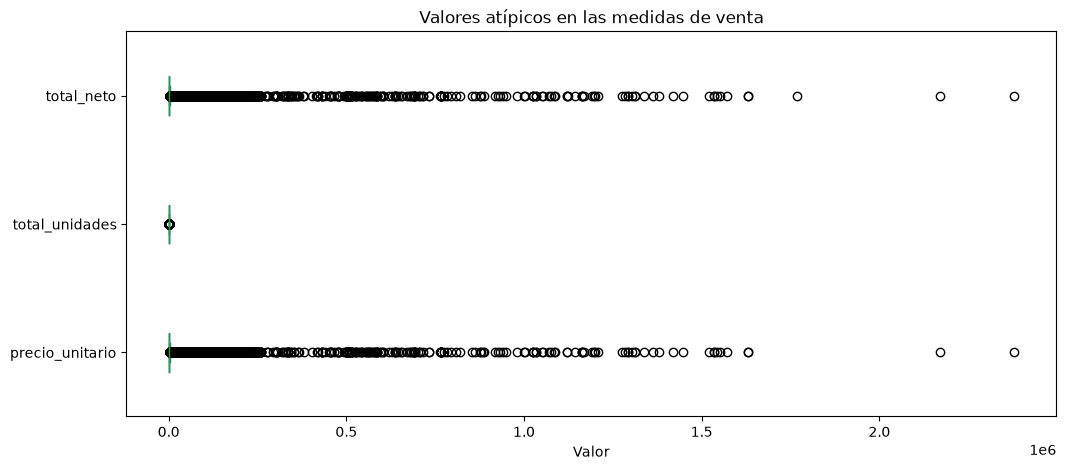

In [23]:
#Visualizamos los valores atípicos antes de corregirlos
ventas_procesadas[variables_cuantitativas].plot(kind='box', vert=False, figsize=(12, 5))
plt.title('Valores atípicos en las medidas de venta')
plt.xlabel('Valor')
plt.show()

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Variables cuantitativas a evaluar
variables_a_evaluar = ['total_neto', 'total_unidades', 'precio_unitario']

resultados_normalidad = []

for var in variables_a_evaluar:
    if var in ventas_procesadas.columns:
        datos = ventas_procesadas[var].dropna()
        
        # 1. Asimetría (Skewness) y Curtosis (Kurtosis)
        # Valores normales esperados: Asimetría cercana a 0, Curtosis cercana a 3 (o exceso 0)
        asimetria = datos.skew()
        curtosis = datos.kurt()
        
        # 2. Prueba formal D'Agostino-Pearson (ideal para muestras grandes)
        stat, p_valor = stats.normaltest(datos)
        es_normal = "Sí" if p_valor > 0.05 else "No"
        
        resultados_normalidad.append({
            'Variable': var,
            'Asimetría (Skew)': round(asimetria, 2),
            'Curtosis': round(curtosis, 2),
            'p-valor': f"{p_valor:.4e}",
            '¿Distribución Normal? (α=0.05)': es_normal
        })

df_normalidad = pd.DataFrame(resultados_normalidad)
print(df_normalidad.to_string(index=False))


       Variable  Asimetría (Skew)  Curtosis    p-valor ¿Distribución Normal? (α=0.05)
     total_neto             25.51    879.86 0.0000e+00                             No
 total_unidades             13.13    440.29 0.0000e+00                             No
precio_unitario             25.94    907.69 0.0000e+00                             No


In [29]:
# Evaluamos cómo mejora la asimetría al aplicar escala logarítmica
for col in ['total_neto', 'total_unidades', 'precio_unitario']:
    log_serie = np.log1p(ventas_procesadas[col])
    print(f"{col} -> Asimetría original: {ventas_procesadas[col].skew():.2f} | Asimetría con log: {log_serie.skew():.2f}")


total_neto -> Asimetría original: 25.51 | Asimetría con log: -0.89
total_unidades -> Asimetría original: 13.13 | Asimetría con log: 2.17
precio_unitario -> Asimetría original: 25.94 | Asimetría con log: -0.63


In [31]:
import numpy as np
import pandas as pd

columnas = ['total_neto', 'total_unidades', 'precio_unitario']
resumen_outliers = []

for col in columnas:
    # 1. Datos originales
    orig = ventas_procesadas[col].dropna()
    q1_orig, q3_orig = orig.quantile(0.25), orig.quantile(0.75)
    iqr_orig = q3_orig - q1_orig
    lim_sup_orig = q3_orig + 1.5 * iqr_orig
    lim_inf_orig = q1_orig - 1.5 * iqr_orig
    outliers_orig = orig[(orig < lim_inf_orig) | (orig > lim_sup_orig)].count()
    pct_orig = (outliers_orig / len(orig)) * 100
    
    # 2. Datos con escala logarítmica
    log_data = np.log1p(orig)
    q1_log, q3_log = log_data.quantile(0.25), log_data.quantile(0.75)
    iqr_log = q3_log - q1_log
    lim_sup_log = q3_log + 1.5 * iqr_log
    lim_inf_log = q1_log - 1.5 * iqr_log
    outliers_log = log_data[(log_data < lim_inf_log) | (log_data > lim_sup_log)].count()
    pct_log = (outliers_log / len(log_data)) * 100
    
    resumen_outliers.append({
        'Variable': col,
        'Outliers Originales': outliers_orig,
        '% Outliers Original': f"{pct_orig:.2f}%",
        'Outliers con Log': outliers_log,
        '% Outliers con Log': f"{pct_log:.2f}%"
    })

df_resumen = pd.DataFrame(resumen_outliers)
print(df_resumen.to_string(index=False))


       Variable  Outliers Originales % Outliers Original  Outliers con Log % Outliers con Log
     total_neto                11515              10.06%              6165              5.38%
 total_unidades                16371              14.30%             13132             11.47%
precio_unitario                 9418               8.23%              7148              6.24%


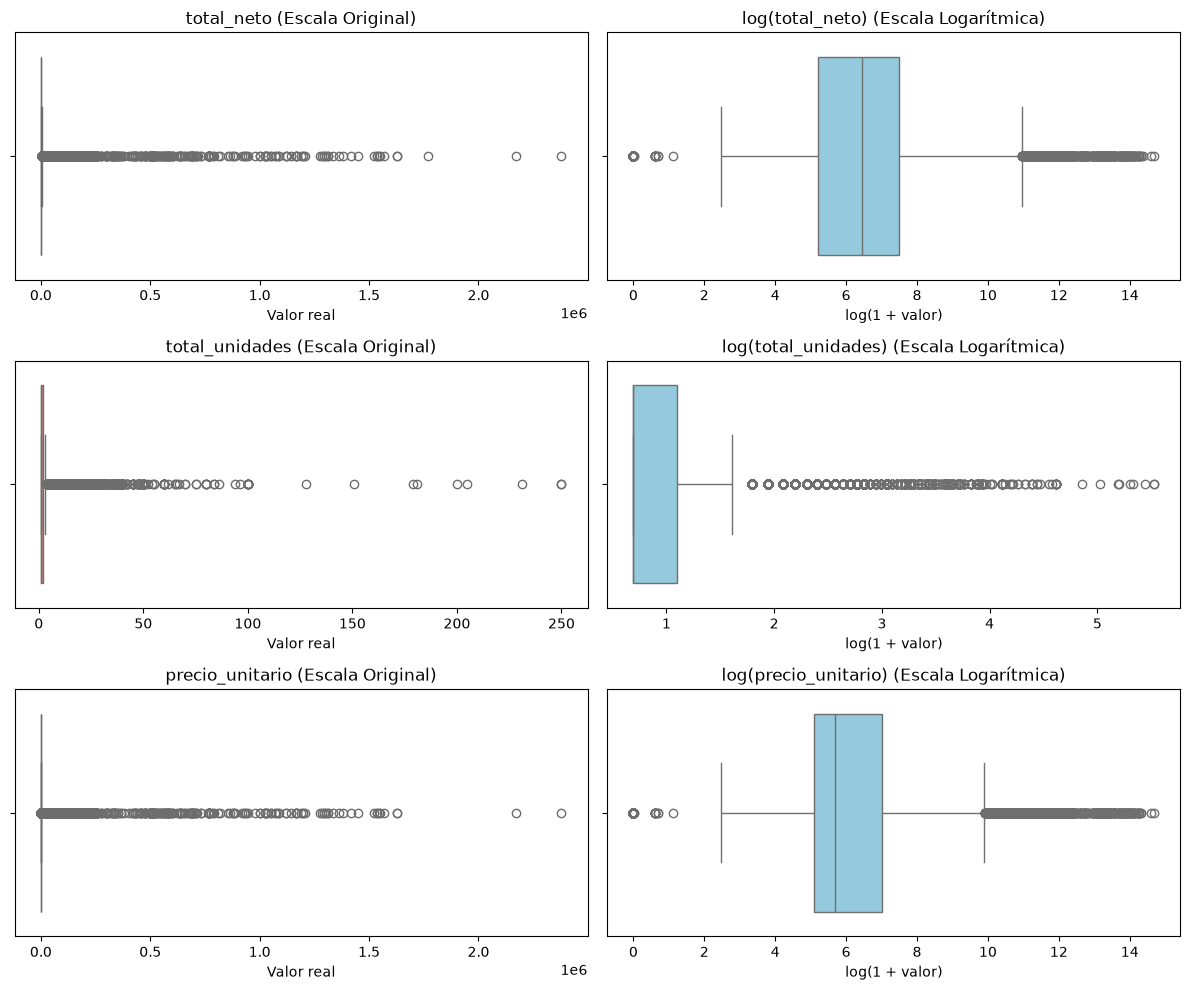

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(len(columnas), 2, figsize=(12, 10))

for i, col in enumerate(columnas):
    # Boxplot Original
    sns.boxplot(x=ventas_procesadas[col], ax=axes[i, 0], color='salmon')
    axes[i, 0].set_title(f"{col} (Escala Original)")
    axes[i, 0].set_xlabel("Valor real")
    
    # Boxplot con Logaritmo
    sns.boxplot(x=np.log1p(ventas_procesadas[col]), ax=axes[i, 1], color='skyblue')
    axes[i, 1].set_title(f"log({col}) (Escala Logarítmica)")
    axes[i, 1].set_xlabel("log(1 + valor)")

plt.tight_layout()
plt.show()


In [38]:
# ==============================================================================
# 1. PREPARACIÓN Y CODIFICACIÓN DE CATEGÓRICAS (TOP-K ONE-HOT ENCODING)
# ==============================================================================
import pandas as pd
import numpy as np

df_modelo = ventas_procesadas.copy()

# A. Agrupación Top-5 para 'marca' (el resto pasa a 'OTRA_MARCA')
top_marcas = df_modelo['marca'].value_counts().head(5).index
df_modelo['marca_agrupada'] = df_modelo['marca'].apply(lambda x: x if x in top_marcas else 'OTRA_MARCA')

# B. Agrupación Top-5 para 'estado' (el resto pasa a 'OTRO_ESTADO')
top_estados = df_modelo['estado'].value_counts().head(5).index
df_modelo['estado_agrupado'] = df_modelo['estado'].apply(lambda x: x if x in top_estados else 'OTRO_ESTADO')

# C. Agrupación Top-5 para 'vendedor' (el resto pasa a 'OTROS_VENDEDORES')
top_vendedores = df_modelo['vendedor'].value_counts().head(5).index
df_modelo['vendedor_agrupado'] = df_modelo['vendedor'].apply(lambda x: x if x in top_vendedores else 'OTROS_VENDEDORES')

# D. Aplicamos One-Hot Encoding con drop_first=True para regresión lineal
df_dummies = pd.get_dummies(
    df_modelo[['marca_agrupada', 'estado_agrupado', 'vendedor_agrupado']],
    drop_first=True,
    dtype=int
)

# Unimos las variables cuantitativas con las nuevas variables dummy
df_regresion = pd.concat([df_modelo[['total_neto', 'total_unidades', 'precio_unitario']], df_dummies], axis=1)

print(f"Dimensiones del dataset listo para modelar: {df_regresion.shape}")
df_regresion.head()


Dimensiones del dataset listo para modelar: (114501, 18)


,total_neto,total_unidades,precio_unitario,marca_agrupada_AIDITE,marca_agrupada_HUGE,marca_agrupada_JENSE,marca_agrupada_OTRA_MARCA,marca_agrupada_VITA,estado_agrupado_Estado de México,estado_agrupado_Jalisco,estado_agrupado_OTRO_ESTADO,estado_agrupado_Puebla,estado_agrupado_Querétaro,vendedor_agrupado_DIEGO,vendedor_agrupado_ESMERALDA,vendedor_agrupado_LUIS,vendedor_agrupado_OTROS_VENDEDORES,vendedor_agrupado_RENE
0,172.41,1,172.413793,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
1,172.41,1,172.413793,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
2,344.83,2,172.413793,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
3,344.83,2,172.413793,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
4,156.74,1,156.740000,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0


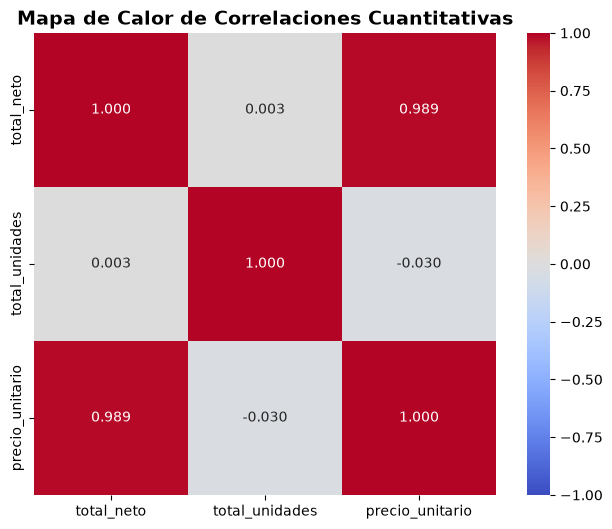

Matriz de Correlación de Pearson:
                 total_neto  total_unidades  precio_unitario
total_neto         1.000000        0.003430         0.989315
total_unidades     0.003430        1.000000        -0.029744
precio_unitario    0.989315       -0.029744         1.000000


In [39]:
# ==============================================================================
# 2. HEATMAP DE CORRELACIÓN ENTRE VARIABLES CUANTITATIVAS
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

cuantitativas = ['total_neto', 'total_unidades', 'precio_unitario']
matriz_corr = df_regresion[cuantitativas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, cbar=True, square=True)
plt.title("Mapa de Calor de Correlaciones Cuantitativas", fontsize=14, weight='bold')
plt.show()

print("Matriz de Correlación de Pearson:")
print(matriz_corr)


=== REGRESIÓN LINEAL SIMPLE: MAYOR CORRELACIÓN ===
Ecuación: total_neto = 723.94 + (1.0104 * precio_unitario)
Pendiente (Beta 1):  1.0104
Intercepto (Beta 0): 723.9406
Coeficiente R²:      0.9787


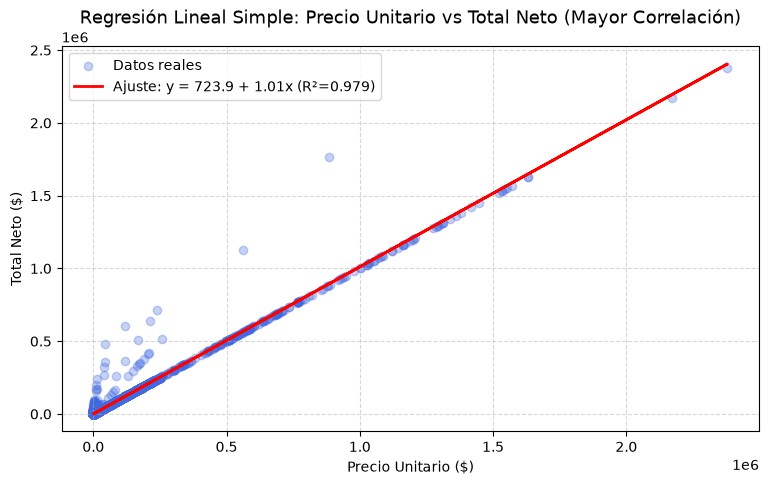

In [43]:
# ==============================================================================
# 3. REGRESIÓN LINEAL SIMPLE CON LA MAYOR CORRELACIÓN REAL (PRECIO VS NETO)
# ==============================================================================
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# X: precio_unitario (independiente), y: total_neto (dependiente)
X_simple = df_regresion[['precio_unitario']]
y_simple = df_regresion['total_neto']

modelo_simple = LinearRegression()
modelo_simple.fit(X_simple, y_simple)

beta_1 = modelo_simple.coef_[0]
beta_0 = modelo_simple.intercept_
r2_simple = r2_score(y_simple, modelo_simple.predict(X_simple))

print("=== REGRESIÓN LINEAL SIMPLE: MAYOR CORRELACIÓN ===")
print(f"Ecuación: total_neto = {beta_0:.2f} + ({beta_1:.4f} * precio_unitario)")
print(f"Pendiente (Beta 1):  {beta_1:.4f}")
print(f"Intercepto (Beta 0): {beta_0:.4f}")
print(f"Coeficiente R²:      {r2_simple:.4f}")

# Gráfica de Dispersión con la Recta de Ajuste
plt.figure(figsize=(9, 5))
plt.scatter(X_simple, y_simple, color='royalblue', alpha=0.3, label='Datos reales')
plt.plot(X_simple, modelo_simple.predict(X_simple), color='red', linewidth=2, 
         label=f'Ajuste: y = {beta_0:.1f} + {beta_1:.2f}x (R²={r2_simple:.3f})')
plt.title("Regresión Lineal Simple: Precio Unitario vs Total Neto (Mayor Correlación)", fontsize=13)
plt.xlabel("Precio Unitario ($)")
plt.ylabel("Total Neto ($)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [41]:
# ==============================================================================
# 4. REGRESIÓN LINEAL MÚLTIPLE (PUNTO 6)
# ==============================================================================
# MODELO 1: Objetivo -> 'total_neto'
X_mult_1 = df_regresion.drop(columns=['total_neto'])
y_mult_1 = df_regresion['total_neto']

modelo_mult_1 = LinearRegression()
modelo_mult_1.fit(X_mult_1, y_mult_1)
r2_mult_1 = r2_score(y_mult_1, modelo_mult_1.predict(X_mult_1))

# MODELO 2: Objetivo -> 'total_unidades'
X_mult_2 = df_regresion.drop(columns=['total_unidades'])
y_mult_2 = df_regresion['total_unidades']

modelo_mult_2 = LinearRegression()
modelo_mult_2.fit(X_mult_2, y_mult_2)
r2_mult_2 = r2_score(y_mult_2, modelo_mult_2.predict(X_mult_2))

print(f"R² Modelo Múltiple 1 (total_neto):     {r2_mult_1:.4f}  (vs {r2_simple:.4f} en simple)")
print(f"R² Modelo Múltiple 2 (total_unidades): {r2_mult_2:.4f}")


R² Modelo Múltiple 1 (total_neto):     0.9802  (vs 0.0000 en simple)
R² Modelo Múltiple 2 (total_unidades): 0.1660


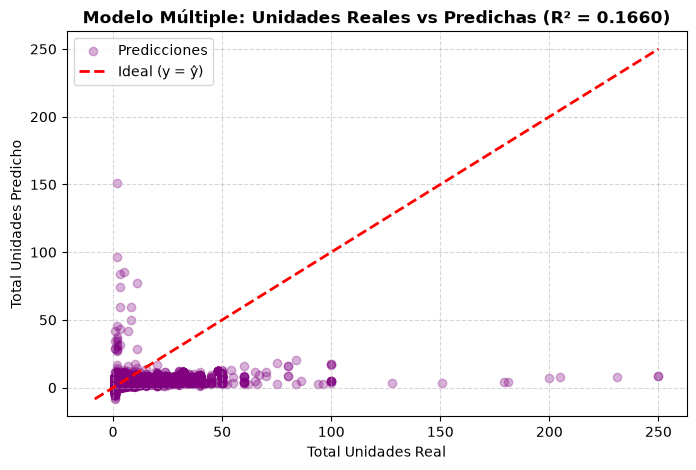

In [44]:
# ==============================================================================
# GRÁFICA: REGRESIÓN LINEAL MÚLTIPLE (total_unidades)
# ==============================================================================
y_pred_2 = modelo_mult_2.predict(X_mult_2)

plt.figure(figsize=(8, 5))
plt.scatter(y_mult_2, y_pred_2, color='purple', alpha=0.3, label='Predicciones')
min_u = min(y_mult_2.min(), y_pred_2.min())
max_u = max(y_mult_2.max(), y_pred_2.max())
plt.plot([min_u, max_u], [min_u, max_u], color='red', linestyle='--', linewidth=2, label='Ideal (y = ŷ)')
plt.title(f"Modelo Múltiple: Unidades Reales vs Predichas (R² = {r2_mult_2:.4f})", fontsize=12, weight='bold')
plt.xlabel("Total Unidades Real")
plt.ylabel("Total Unidades Predicho")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [46]:

# 1. Obtenemos las desviaciones estándar de X y de y
desv_y = df_regresion['total_neto'].std()
desv_X = df_regresion[X_mult_1.columns].std()

# 2. Calculamos los Coeficientes Estandarizados (Beta*) para ponerlos en la escala de Pearson
beta_estandarizado = modelo_mult_1.coef_ * (desv_X / desv_y)

# 3. Construimos la tabla comparativa rigurosa
tabla_comparativa_exacta = pd.DataFrame({
    'Variable': X_mult_1.columns,
    'Correlación Simple (Pearson r)': [df_regresion[col].corr(df_regresion['total_neto']) for col in X_mult_1.columns],
    'Beta Estandarizado (Múltiple)': beta_estandarizado.values,
    'Beta en Pesos Reales ($)': modelo_mult_1.coef_
})

print("=== COMPARACIÓN: PEARSON VS COEFICIENTE MÚLTIPLE ESTANDARIZADO ===")
print(tabla_comparativa_exacta.round(4).to_string(index=False))


=== COMPARACIÓN: PEARSON VS COEFICIENTE MÚLTIPLE ESTANDARIZADO ===
                          Variable  Correlación Simple (Pearson r)  Beta Estandarizado (Múltiple)  Beta en Pesos Reales ($)
                    total_unidades                          0.0034                         0.0356                  308.7369
                   precio_unitario                          0.9893                         0.9889                    1.0100
             marca_agrupada_AIDITE                         -0.0117                        -0.0028                 -320.1509
               marca_agrupada_HUGE                         -0.0214                        -0.0143                -3046.9280
              marca_agrupada_JENSE                         -0.0103                        -0.0036                 -738.0880
         marca_agrupada_OTRA_MARCA                          0.0940                        -0.0058                 -737.7667
               marca_agrupada_VITA                         -0.098